# Analiza danych — Laptop Store

Dane pochodzą z pełnego przebiegu scrapera w Selenium (`uv run python -m scraper`):
8 podstron katalogu, 448 wierszy listy, strona szczegółów i zakładka „Specyfikacja” każdego produktu.

| Plik | Zawartość |
|---|---|
| `output/laptops.csv` | dane oczyszczone, bez duplikatów |
| `output/laptops_raw.csv` | surowe teksty ze strony, z duplikatami |
| `output/laptops_summary.json` | podsumowanie przebiegu: czas, błędy, 429, odrzucone wartości |

Wykresy zapisują się do `report/figures/` i trafiają do sprawozdania.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from scraper import analysis

%matplotlib inline
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

OUTPUT = Path("..") / "output"
FIGURES = Path("..") / ".." / "report" / "figures"

df = analysis.load_dataset(OUTPUT / "laptops.csv")
raw = analysis.load_raw(OUTPUT / "laptops_raw.csv")
summary = json.loads((OUTPUT / "laptops_summary.json").read_text("utf-8"))
print(f"rekordy: {len(df)}, kolumny: {len(df.columns)}, wiersze surowe: {len(raw)}")
print(
    f"czas przebiegu: {summary['duration_seconds']} s, odpowiedzi API: "
    f"{summary['source_stats']['api_responses']}, HTTP 429: "
    f"{summary['source_stats']['http_429_responses']}, "
    f"nieudane produkty: {len(summary['collection']['failed_products'])}"
)

rekordy: 438, kolumny: 28, wiersze surowe: 448
czas przebiegu: 584.9 s, odpowiedzi API: 908, HTTP 429: 0, nieudane produkty: 0


## 1. Kontrola jakości danych

Ta część sprawdza, czy parser zadziałał poprawnie, zanim zaczniemy wyciągać wnioski z danych.

### 1.1 Liczba rekordów i braki w każdej kolumnie

In [2]:
analysis.missing_values(df)

,dtype,missing,missing_pct
id,int64,0,0.0
name,str,0,0.0
url,str,0,0.0
price_original,str,0,0.0
currency,str,0,0.0
price,float64,0,0.0
price_pln,float64,0,0.0
category,str,0,0.0
brand,str,0,0.0
availability,str,0,0.0


**Interpretacja.** 438 rekordów i 28 kolumn: 24 atrybuty ze sklepu (12 z listy, 6 ze strony szczegółów,
6 z zakładki „Specyfikacja”) oraz 4 kolumny pomocnicze (`price_original`, `price_pln`, `source_page`, `layout`).

Braki występują tylko w dwóch kolumnach: `rating` (98 szt., 22,4%) i `warranty_months` (96 szt., 21,9%).
To utrudnienie celowo wprowadzone przez autora serwisu — wartość „—” na stronie. Parser zamienił ją na pustą
komórkę, a nie na wyjątek ani na zero. Pozostałe kolumny nie mają braków, co oznacza, że każda strona
szczegółów i każda zakładka specyfikacji została wczytana (0 nieudanych produktów w podsumowaniu).

### 1.2 Duplikaty przed i po odrzuceniu

In [3]:
counts, duplicated_rows = analysis.duplicates(raw, df)
display(counts)
duplicated_rows

,rows,unique_ids,duplicate_rows
before (raw),448,438,10
after (clean),438,438,0


,id,name,source_page,layout
170,168,"ASUS ROG Strix G16 17.3"" i7-13650HX/32GB/512GB...",4,card
374,168,"ASUS ROG Strix G16 17.3"" i7-13650HX/32GB/512GB...",7,table
187,185,"HP EliteBook 840 14"" Ryzen 5 7640HS/16GB/512GB",4,card
413,185,"HP EliteBook 840 14"" Ryzen 5 7640HS/16GB/512GB",8,card
194,192,"Acer Predator Helios 16 17.3"" i9-13980HX/16GB/...",4,card
422,192,"Acer Predator Helios 16 17.3"" i9-13980HX/16GB/...",8,card
212,209,"HP Omen 16 16"" Ryzen 9 7945HX/64GB/2TB/RTX 4070",4,card
434,209,"HP Omen 16 16"" Ryzen 9 7945HX/64GB/2TB/RTX 4070",8,card
222,219,"HP Victus 15 17.3"" i7-13650HX/16GB/1TB/RTX 4070",4,card
242,219,"HP Victus 15 17.3"" i7-13650HX/16GB/1TB/RTX 4070",5,table


**Interpretacja.** Przed czyszczeniem 448 wierszy, po odrzuceniu 438 — usunięto 10 duplikatów. Każdy duplikat
leży na innej podstronie niż oryginał, a część pary jest w tabeli, część w kartach (`layout`). Deduplikacja
po atrybucie `data-id` działa więc niezależnie od struktury, w której rekord się pojawił. Zostaje pierwsze
wystąpienie, dlatego `source_page` wskazuje wcześniejszą podstronę.

### 1.3 Typy kolumn i walidacja wartości

In [4]:
print("odrzucone wartości:", summary["cleaning"]["rejected_values"] or "brak")
mismatches = summary["cleaning"]["listing_detail_mismatches"]
print("różnice lista vs strona produktu:", mismatches or "brak")
df.dtypes.to_frame("dtype").T

odrzucone wartości: brak
różnice lista vs strona produktu: brak


,id,name,url,price_original,currency,price,price_pln,category,brand,availability,rating,review_count,date_added,warranty_months,screen_size_in,resolution,weight_kg,os,color,release_year,cpu,ram_gb,storage_gb,storage_type,gpu,battery_wh,source_page,layout
dtype,int64,str,str,str,str,float64,float64,str,str,str,float64,Int64,datetime64[us],Int64,float64,str,float64,str,str,Int64,str,Int64,Int64,str,str,Int64,Int64,str


**Interpretacja.** Wszystkie kolumny liczbowe mają typ liczbowy: ceny, ocena, przekątna i waga to `float64`;
liczby całkowite z możliwymi brakami to `Int64` (pandas nie zamienia ich na `float`); `date_added` to
`datetime64`. Walidacja zakresów (np. ocena 0–5, cena > 0, data nie z przyszłości) nie odrzuciła ani jednej
wartości.

Dodatkowo scraper porównuje pola widoczne zarówno na liście, jak i na stronie produktu (nazwa, cena, waluta,
kategoria, ocena, data…). Zero różnic oznacza, że selektory w tabeli, w kartach i na stronie szczegółów
wskazują te same dane.

### 1.4 Wartości odstające (reguła 1,5 × IQR)

In [5]:
analysis.outlier_counts(df).to_frame("liczba wartości odstających")

,liczba wartości odstających
price_pln,33
rating,4
review_count,17
warranty_months,75
screen_size_in,0
weight_kg,0
release_year,12
ram_gb,0
storage_gb,42
battery_wh,0


In [6]:
price_outliers = analysis.iqr_outliers(df, "price_pln")
print(price_outliers["category"].value_counts().to_dict())
print("wszystkie z dedykowaną kartą RTX:", price_outliers["gpu"].str.startswith("NVIDIA").all())
price_outliers.sort_values("price_pln", ascending=False)[
    ["id", "name", "category", "price_original", "currency", "price_pln"]
].head(10)

{'Gamingowy': 33}
wszystkie z dedykowaną kartą RTX: True


,id,name,category,price_original,currency,price_pln
141,142,"Lenovo Legion Pro 7 17.3"" i9-13980HX/64GB/2TB/...",Gamingowy,"17 199,00 zł",PLN,17199.00
357,358,"Dell G16 15.6"" Ryzen 7 7840HS/64GB/512GB/RTX 4080",Gamingowy,"15 399,00 zł",PLN,15399.00
377,378,"MSI Raider GE78 15.6"" i7-13650HX/64GB/2TB/RTX ...",Gamingowy,"15 399,00 zł",PLN,15399.00
43,44,"Dell Alienware m16 16"" Ryzen 7 7840HS/32GB/2TB...",Gamingowy,"14 899,00 zł",PLN,14899.00
252,253,"HP Victus 15 17.3"" i7-13650HX/64GB/2TB/RTX 4080",Gamingowy,"14 799,00 zł",PLN,14799.00
64,65,"ASUS ROG Strix G16 16"" i7-13650HX/64GB/512GB/R...",Gamingowy,"14 699,00 zł",PLN,14699.00
167,168,"ASUS ROG Strix G16 17.3"" i7-13650HX/32GB/512GB...",Gamingowy,"$3,568.99",USD,13934.05
322,323,"ASUS ROG Strix G16 15.6"" Ryzen 7 7840HS/32GB/5...",Gamingowy,"13 899,00 zł",PLN,13899.00
96,97,"MSI Raider GE78 16"" Ryzen 9 7945HX/64GB/2TB/RT...",Gamingowy,"13 699,00 zł",PLN,13699.00
213,214,"ASUS TUF Gaming A15 16"" Ryzen 9 7945HX/64GB/2T...",Gamingowy,"€3,092.99",EUR,13518.22


In [7]:
naive = raw["price"].map(analysis.naive_price)
pd.DataFrame(
    {
        "parser naiwny (same cyfry)": naive.describe()[["min", "50%", "max"]],
        "parser projektu (price_pln)": df["price_pln"].describe()[["min", "50%", "max"]],
    }
)

,parser naiwny (same cyfry),parser projektu (price_pln)
min,32899.0,1284.44
50%,469900.0,5199.00
max,1719900.0,17199.00


In [8]:
print(
    "waga dokładnie 0,9 kg:",
    (df["weight_kg"] == 0.9).sum(),
    "szt.",
    df.loc[df["weight_kg"] == 0.9, "category"].value_counts().to_dict(),
)
analysis.iqr_outliers(df, "rating")[["id", "name", "rating", "review_count"]]

waga dokładnie 0,9 kg: 31 szt. {'Ultrabook': 29, 'Biznesowy': 2}


,id,name,rating,review_count
172,173,"Dell XPS 13 14"" Ryzen 7 7735HS/16GB/1TB",2.8,25
243,244,"HP Omen 16 15.6"" i9-13980HX/16GB/512GB/RTX 4050",2.7,25
305,306,"Lenovo Legion Pro 7 17.3"" Ryzen 9 7945HX/32GB/...",2.2,3
322,323,"ASUS ROG Strix G16 15.6"" Ryzen 7 7840HS/32GB/5...",2.7,9


**Interpretacja — anomalia w danych czy błąd parsera?**

- **`price_pln` (33 szt.)** — wszystkie to laptopy gamingowe z dedykowaną kartą RTX, w cenie 11,9–17,2 tys. zł.
  To prawdziwe dane: górny ogon rozkładu cen. Wśród nich są ceny przeliczone z USD i EUR, które mieszczą się
  w tym samym przedziale co ceny w złotych — przeliczenie walut działa.
- **Błąd parsera wyglądałby inaczej.** „Naiwny” parser, który wycina z ceny same cyfry, zamienia
  „1 299,00 zł” na 129900: mediana wyszłaby ~470 tys., a maksimum ~1,7 mln zł, czyli wartości ok. 100 razy za
  duże. W naszych danych maksimum to 17 199 zł — tego błędu nie ma.
- **`review_count` (17 szt.)** — rozkład liczby opinii jest silnie prawoskośny (kilka produktów ma 300–600 opinii,
  mediana 56). To naturalny długi ogon popularności, nie błąd.
- **`rating` (4 szt.)** — oceny 2,2–2,8. Produkty z niską oceną mają mało opinii, więc pojedyncza ocena mocno
  wpływa na średnią — wiarygodna anomalia.
- **`warranty_months` (75), `storage_gb` (42), `release_year` (12)** — to artefakt metody, a nie danych:
  te cechy przyjmują kilka dyskretnych wartości (np. gwarancja 12/24/36 mies., Q1 = Q3 = 24), więc IQR = 0 i każda
  wartość różna od 24 jest „odstająca”.
- **`weight_kg`** — brak wartości odstających, ale moda to 0,9 kg (31 produktów, prawie same ultrabooki). Waga
  jest „przycięta” od dołu w danych źródłowych; to cecha zbioru, nie parsera (te same 0,9 kg są na stronie).

### 1.5 Dodatkowe kontrole spójności

In [9]:
analysis.name_consistency(df)

,matching,of
name_parsed,438,438
screen,438,438
ram,438,438
storage,438,438
gpu,438,438


In [10]:
df.groupby("currency")["price_pln"].agg(["count", "median", "min", "max"]).round(0)

,count,median,min,max
currency,,,,
EUR,44,5031.0,1726.0,13518.0
PLN,368,5199.0,1299.0,17199.0
USD,26,4792.0,1284.0,13934.0


**Interpretacja.** Nazwa produktu zawiera przekątną, RAM, dysk i kartę graficzną (np.
`…16" i7-13650HX/32GB/1TB/RTX 4060`). Wyciągnięte z nazwy wartości zgadzają się z kolumnami ze specyfikacji
w 438/438 rekordach — dane z listy i z zakładki „Specyfikacja” zostały poprawnie połączone po `id`.

Mediany cen po przeliczeniu na PLN są podobne dla wszystkich walut (EUR ok. 5,0 tys., USD ok. 4,8 tys.,
PLN ok. 5,2 tys.), więc kurs NBP i odczyt formatu `$1,239.99` są poprawne — błąd w kursie lub w separatorze
przesunąłby całą grupę.

#### Weryfikacja z danymi źródłowymi autora

Ponieważ pracujemy w parze, mamy dostęp do pliku, z którego serwis generuje strony
(`shop/data/products.json`). Pozwala to sprawdzić parser „od zewnątrz”: każde pole porównujemy z oryginałem.

In [11]:
from datetime import datetime

from scraper.cleaning import parse_date, parse_price

truth = json.loads((Path("..") / ".." / "shop" / "data" / "products.json").read_text("utf-8"))
truth_by_id = {product["id"]: product for product in truth}
scraped_on = datetime.fromisoformat(summary["started_at"]).date()
fields = [
    "name",
    "currency",
    "category",
    "brand",
    "availability",
    "rating",
    "review_count",
    "warranty_months",
    "screen_size_in",
    "resolution",
    "weight_kg",
    "os",
    "color",
    "release_year",
    "cpu",
    "ram_gb",
    "storage_gb",
    "storage_type",
    "gpu",
    "battery_wh",
]

differences = []
for row in df.to_dict("records"):
    source = truth_by_id[row["id"]]
    expected = {field: source[field] for field in fields}
    expected["price"] = parse_price(source["price"])
    expected["date_added"] = pd.Timestamp(parse_date(source["date_added"], scraped_on))
    for field, value in expected.items():
        got = row[field]
        same = pd.isna(got) if value is None else got == value
        if not same:
            differences.append((row["id"], field, got, value))

checked = len(fields) + 2
print(f"sprawdzone pola: {len(df)} produktów × {checked} pól = {len(df) * checked}")
print(f"produkty w źródle: {len(truth_by_id)}, w CSV: {df['id'].nunique()}")
print(f"różnice: {len(differences)}")

sprawdzone pola: 438 produktów × 22 pól = 9636
produkty w źródle: 438, w CSV: 438
różnice: 0


### 1.6 Wniosek z kontroli jakości

Parser jest poprawny: 438/438 unikalnych produktów, 0 nieudanych stron, 0 odrzuconych wartości,
0 niezgodności między listą a stroną produktu, a porównanie z danymi źródłowymi autora nie wykazało
żadnej różnicy w 9636 sprawdzonych polach. Braki są tylko tam, gdzie serwis celowo pokazuje „—”.

**Co poprawiłem dzięki testom i kontroli:**

1. **Paginacja** — test jednostkowy `collect` wykazał, że bez parametru `--pages` scraper kończył na pierwszej
   podstronie (`max_pages or page`). Bez tej poprawki dostalibyśmy 56 zamiast 448 wierszy.
2. **Ponawianie przy HTTP 429 w Selenium** — test z wymuszonym limitem (`--delay 0`) pokazał 4 z 40 produktów
   utraconych: ponowna próba przeładowywała całą stronę produktu (2 zapytania), a `Retry-After` przy oknie
   przesuwnym zwalnia tylko jedno miejsce. Teraz ponawiane jest tylko nieudane zapytanie (ponowne kliknięcie
   zakładki) — wynik 40/40.
3. **Czas połączeń** — tryb API wykonywał 22 zapytania w 48 s. Przyczyna: na Windows `localhost` najpierw próbuje
   IPv6, a serwer Flask słucha tylko na IPv4 (2 s straty na połączenie). Domyślny adres to teraz `127.0.0.1`.
4. **Ceny** — separator dziesiętny jest rozpoznawany po pozycji (1–2 cyfry na końcu), a nie po walucie,
   co obsługuje „4 199,00 zł”, „$1,239.99” i „€999.99” jedną funkcją; test regresji pilnuje, by
   „1 299,00 zł” nie stało się 129900.

## 2. Statystyki opisowe

In [12]:
analysis.descriptive_statistics(df)

,count,mean,median,mode,std,min,q1,q3,max
price_pln,438,5892.64,5199.00,2299.0,3231.23,1284.44,3899.00,7049.00,17199.00
rating,340,4.27,4.30,4.4,0.44,2.20,4.00,4.60,5.00
review_count,438,78.90,56.00,2.0,79.03,1.00,24.00,111.00,621.00
warranty_months,342,24.88,24.00,24.0,5.56,12.00,24.00,24.00,36.00
screen_size_in,438,15.05,15.60,14.0,1.40,13.30,14.00,16.00,17.30
weight_kg,438,1.72,1.74,0.9,0.64,0.90,1.11,2.33,2.95
release_year,438,2024.32,2024.00,2024.0,1.03,2022.00,2024.00,2025.00,2026.00
ram_gb,438,22.74,16.00,16.0,15.76,8.00,8.00,32.00,64.00
storage_gb,438,857.42,1024.00,1024.0,480.50,256.00,512.00,1024.00,2048.00
battery_wh,438,61.03,60.50,69.0,15.05,35.00,49.00,69.00,99.00


**Interpretacja.**

- **Cena (PLN):** średnia 5893 zł > mediana 5199 zł — rozkład prawoskośny, ciągnięty w górę przez laptopy
  gamingowe. Moda 2299 zł to typowa cena laptopa budżetowego (ceny kończą się na „99”, więc się powtarzają).
  Połowa produktów kosztuje 3899–7049 zł (Q1–Q3), rozpiętość 1284–17 199 zł.
- **Ocena:** średnio 4,27, mediana 4,3 — oceny skupione wysoko, jak w prawdziwych sklepach; liczona z 340
  produktów, które mają ocenę.
- **Liczba opinii:** średnia 79 vs mediana 56, moda 2 — wiele nowych produktów z kilkoma opiniami i nieliczne
  bardzo popularne.
- **RAM:** mediana i moda 16 GB, zakres 8–64 GB; **dysk:** mediana 1 TB.
- **Gwarancja:** najczęściej 24 mies. (78% produktów z podaną gwarancją; Q1 = mediana = Q3 = 24), 12 mies. tylko w kategorii budżetowej, 36 mies. tylko w biznesowej.
- **Rok premiery:** 2022–2026, mediana 2024.

## 3. Wykresy

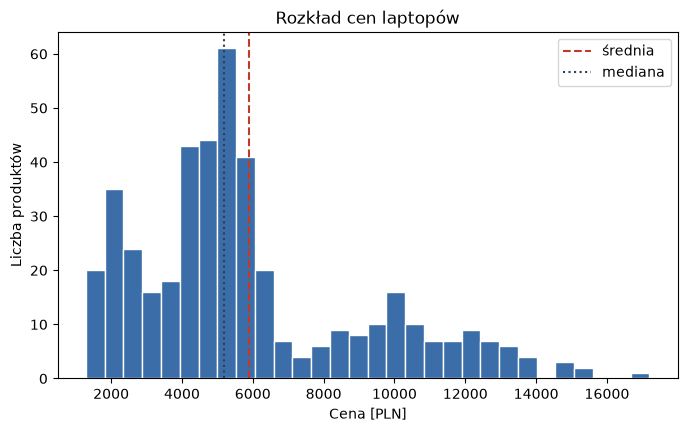

In [13]:
figure = analysis.price_histogram(df)
analysis.save_figure(figure, FIGURES, "histogram_price")
plt.show()

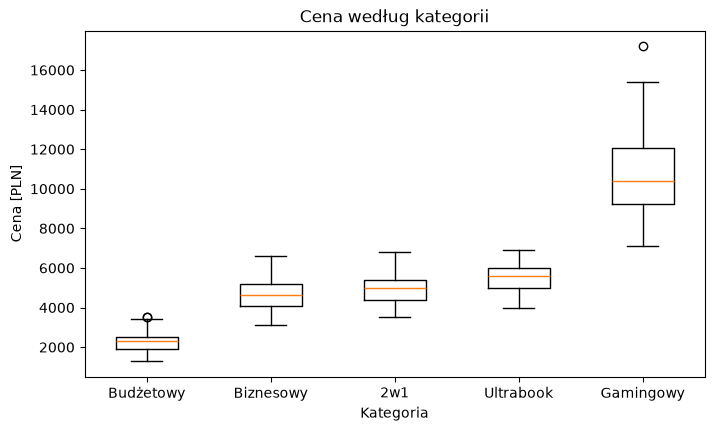

,count,min,25%,50%,75%,max
category,,,,,,
2w1,77.0,3499.0,4399.0,4999.0,5399.0,6799.0
Biznesowy,82.0,3099.0,4099.0,4649.0,5199.0,6599.0
Budżetowy,90.0,1284.0,1899.0,2299.0,2529.0,3499.0
Gamingowy,110.0,7099.0,9224.0,10399.0,12074.0,17199.0
Ultrabook,79.0,3999.0,4999.0,5599.0,5999.0,6899.0


In [14]:
figure = analysis.price_boxplot_by_category(df)
analysis.save_figure(figure, FIGURES, "boxplot_price_by_category")
plt.show()
quartiles = ["count", "min", "25%", "50%", "75%", "max"]
df.groupby("category")["price_pln"].describe()[quartiles].round(0)

**Interpretacja.** Histogram ma dwa skupienia: duże w przedziale ok. 2–7 tys. zł (laptopy budżetowe, biznesowe,
ultrabooki i 2w1) oraz mniejsze powyżej ok. 7 tys. zł (gamingowe). Wykres pudełkowy pokazuje, skąd to się bierze:
kategoria „Gamingowy” ma medianę ok. 10,4 tys. zł i nie zachodzi na pozostałe kategorie, a „Budżetowy” (mediana
ok. 2,3 tys. zł) jest wyraźnie najtańszy. Biznesowe, 2w1 i ultrabooki leżą blisko siebie (mediany 4,6–5,6 tys.).
Wąskie pudełka poza kategorią gamingową oznaczają, że cena w dużej mierze wynika z kategorii.

## 4. Korelacje

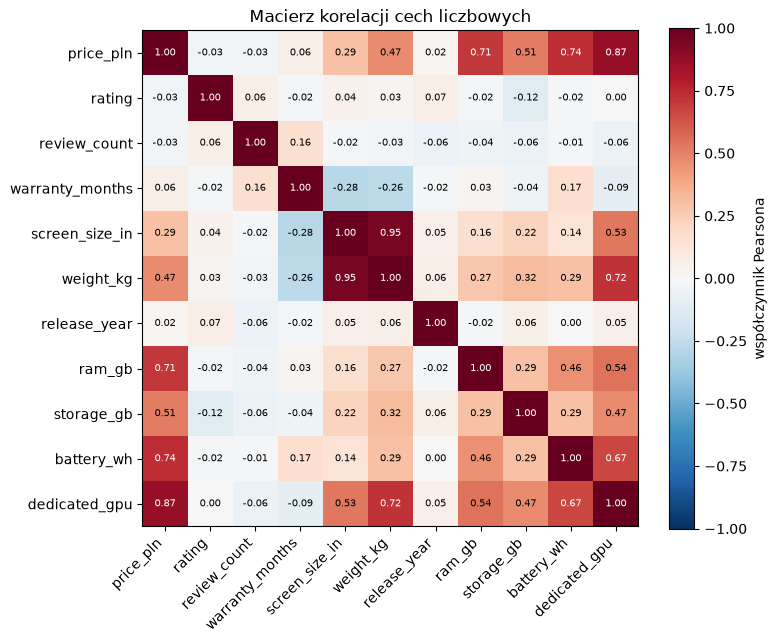

,korelacja z ceną
dedicated_gpu,0.87
battery_wh,0.74
ram_gb,0.71
storage_gb,0.51
weight_kg,0.47
screen_size_in,0.29
warranty_months,0.06
release_year,0.02
review_count,-0.03
rating,-0.03


In [15]:
corr = analysis.correlations(df)
figure = analysis.correlation_heatmap(corr)
analysis.save_figure(figure, FIGURES, "correlation_heatmap")
plt.show()
corr["price_pln"].drop("price_pln").sort_values(ascending=False).to_frame("korelacja z ceną")

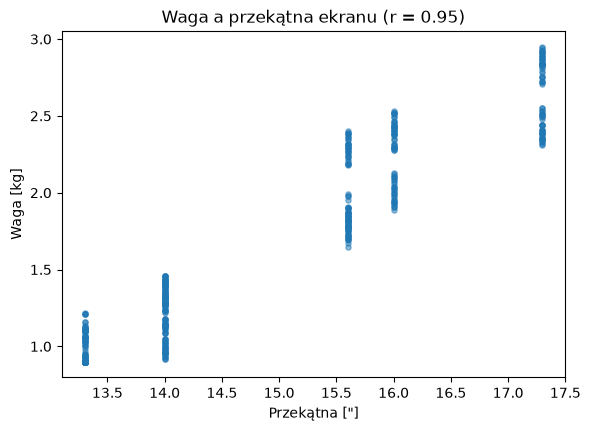

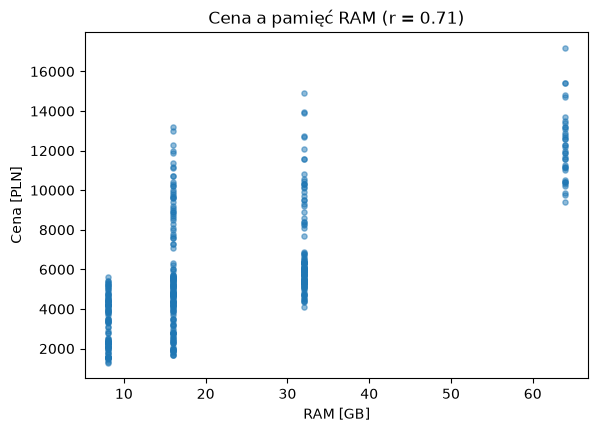

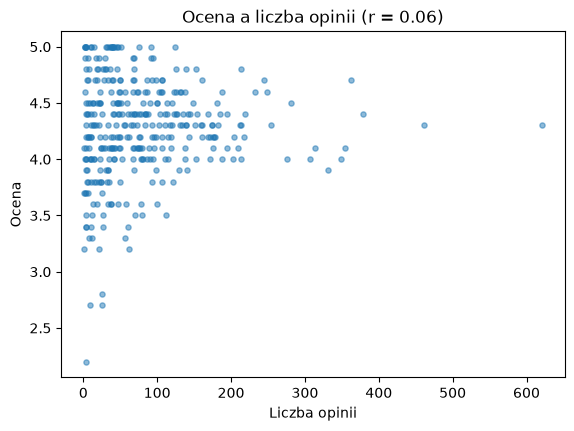

In [16]:
figure = analysis.scatter(
    df, "screen_size_in", "weight_kg", "Waga a przekątna ekranu", 'Przekątna ["]', "Waga [kg]"
)
analysis.save_figure(figure, FIGURES, "scatter_weight_screen")
plt.show()

figure = analysis.scatter(df, "ram_gb", "price_pln", "Cena a pamięć RAM", "RAM [GB]", "Cena [PLN]")
analysis.save_figure(figure, FIGURES, "scatter_price_ram")
plt.show()

figure = analysis.scatter(
    df, "review_count", "rating", "Ocena a liczba opinii", "Liczba opinii", "Ocena"
)
analysis.save_figure(figure, FIGURES, "scatter_rating_reviews")
plt.show()

**Interpretacja — czy zależności mają sens merytoryczny?**

- **Waga a przekątna: r = 0,95.** Najsilniejsza zależność w zbiorze i w pełni sensowna: większy ekran to większa
  obudowa, bateria i chłodzenie.
- **Cena a dedykowana karta graficzna: r = 0,87** (zmienna 0/1). Karta RTX to największy pojedynczy składnik ceny
  — mediana ceny z RTX ok. 10,4 tys. zł, bez niej ok. 4,6 tys. zł.
- **Cena a RAM: r = 0,71**, **cena a dysk: r = 0,51** — więcej pamięci kosztuje więcej, sensowne.
- **Cena a bateria: r = 0,74** — tu ostrożnie: to w dużej mierze korelacja pozorna. Duże baterie (do 99 Wh) mają
  laptopy gamingowe, które są drogie z powodu karty graficznej. Zmienną zakłócającą jest kategoria.
- **Ocena a liczba opinii: r ≈ 0,06** — brak zależności liniowej: popularność nie przekłada się na ocenę. Wykres
  rozrzutu pokazuje natomiast, że przy małej liczbie opinii oceny są bardzo rozrzucone (2,2–5,0), a przy dużej
  skupiają się wokół 4,3 — średnia z większej próby jest stabilniejsza (prawo wielkich liczb).
- **Gwarancja a przekątna: r = −0,28** — laptopy biznesowe (mniejsze ekrany) mają często 36 mies. gwarancji,
  a budżetowe 15–17" bywają z 12 mies.

## 5. Selenium a API, surowy HTML a DOM, wydajność

Wyniki narzędzi `python -m scraper --mode api`, `python -m scraper.raw_vs_dom` i `python -m scraper.benchmark`.

In [17]:
api_path = OUTPUT / "laptops_api.csv"
if api_path.exists():
    api = analysis.load_dataset(api_path)
    compared = [c for c in df.columns if c != "layout"]
    same = df[compared].equals(api[compared])
    print(f"Selenium: {len(df)} rekordów, API: {len(api)} rekordów")
    print(f"identyczne (bez kolumny layout): {same}")
else:
    print("brak output/laptops_api.csv — uruchom:")
    print("uv run python -m scraper --mode api --output output/laptops_api")

Selenium: 438 rekordów, API: 438 rekordów
identyczne (bez kolumny layout): True


In [18]:
raw_vs_dom = pd.read_csv(OUTPUT / "raw_vs_dom.csv", encoding="utf-8-sig")
raw_vs_dom

,page,what,raw_html,dom_after_scripts,raw_html_kb,dom_kb
0,/?page=1,records (.catalog .product),0,56,1.2,26.9
1,/?page=2,records (.catalog .product),0,56,1.2,37.2
2,/?page=3,records (.catalog .product),0,56,1.2,27.1
3,/?page=4,records (.catalog .product),0,56,1.2,37.4
4,/?page=5,records (.catalog .product),0,56,1.2,27.1
5,/?page=6,records (.catalog .product),0,56,1.2,37.2
6,/?page=7,records (.catalog .product),0,56,1.2,27.1
7,/?page=8,records (.catalog .product),0,56,1.2,37.2
8,/product.html?id=1,product fields (of 19) before clicking the spe...,0,13,NaN,NaN
9,/product.html?id=1,product fields (of 19) after clicking the spec...,0,19,NaN,NaN


In [19]:
benchmark = pd.read_csv(OUTPUT / "benchmark.csv", encoding="utf-8-sig")
benchmark

,variant,products,duration_s,throttle_wait_s,active_s,peak_memory_mb,api_responses,http_429
0,api,30,37.6,34.4,3.2,78.2,61,0
1,headless,30,44.1,30.9,13.2,746.1,64,0
2,headed,30,45.1,32.0,13.1,757.7,64,0


**Interpretacja.**

- **Surowy HTML a DOM.** W źródle strony pobranym przez `requests` jest 0 rekordów na każdej z 8 podstron
  (dokument ma ok. 1,2 KB — sam szkielet). W drzewie DOM po wykonaniu skryptów i przewinięciu jest 56 rekordów
  na podstronę, razem 448. Na stronie produktu surowy HTML nie zawiera żadnego pola, DOM po załadowaniu ma 13 z 19,
  a 6 pól specyfikacji pojawia się dopiero po kliknięciu zakładki. Wniosek: bez wykonania JavaScriptu
  (przeglądarka) albo bez sięgnięcia do źródła danych (API) nie da się tego serwisu sparsować.
- **API a Selenium.** Oba podejścia dają identyczny zbiór. API jest szybsze i lżejsze: na 30 produktach czas
  „aktywny” (bez celowych odstępów 0,6 s między zapytaniami) to ok. 3 s wobec ok. 13 s w Selenium, a szczyt pamięci
  ok. 80 MB wobec ok. 750 MB (Chrome z procesami potomnymi). Przyczyny: brak renderowania HTML/CSS i wykonywania
  JS, dane od razu w strukturze JSON, cała podstrona w jednym zapytaniu (`limit=56`) zamiast 4 porcji
  doładowywanych przewijaniem. Łączny czas jest podobny, bo ogranicza go uprzejmy odstęp między zapytaniami
  i limit serwera (20 zapytań / 10 s).
- **Headless a okno.** Czas i pamięć są praktycznie takie same — przy tak prostej stronie koszt rysowania okna jest
  pomijalny wobec czasu oczekiwania na serwer. Tryb headless nie wymaga natomiast środowiska graficznego.